In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline


In [4]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [5]:
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


# Step 2: Load the dataset


In [8]:

df = pd.read_csv('/content/pima_indians_diabetes.csv')

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0,1.0
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0,0.0
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0,1.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,0.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1.0


In [9]:
# Display dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (768, 9)

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    float64
 1   Glucose                   768 non-null    float64
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    float64
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    float64
 8   Outcome                   768 non-null    float64
dtypes: float64(9)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
# Check missing values

print("Missing values:")
print(df.isnull().sum())

# Check zero values

print("\nZero values:")
print((df == 0).sum())

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero values:
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


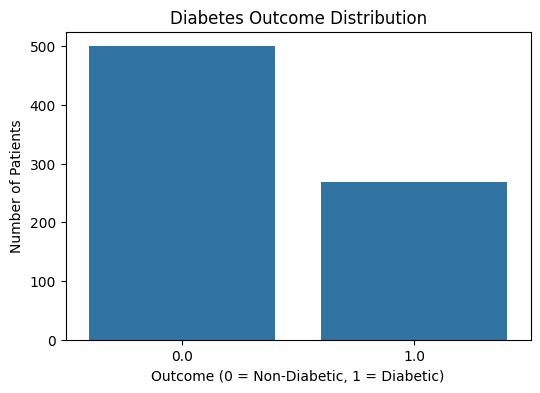

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# Outcome distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Outcome')

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = Non-Diabetic, 1 = Diabetic)")
plt.ylabel("Number of Patients")

plt.show()

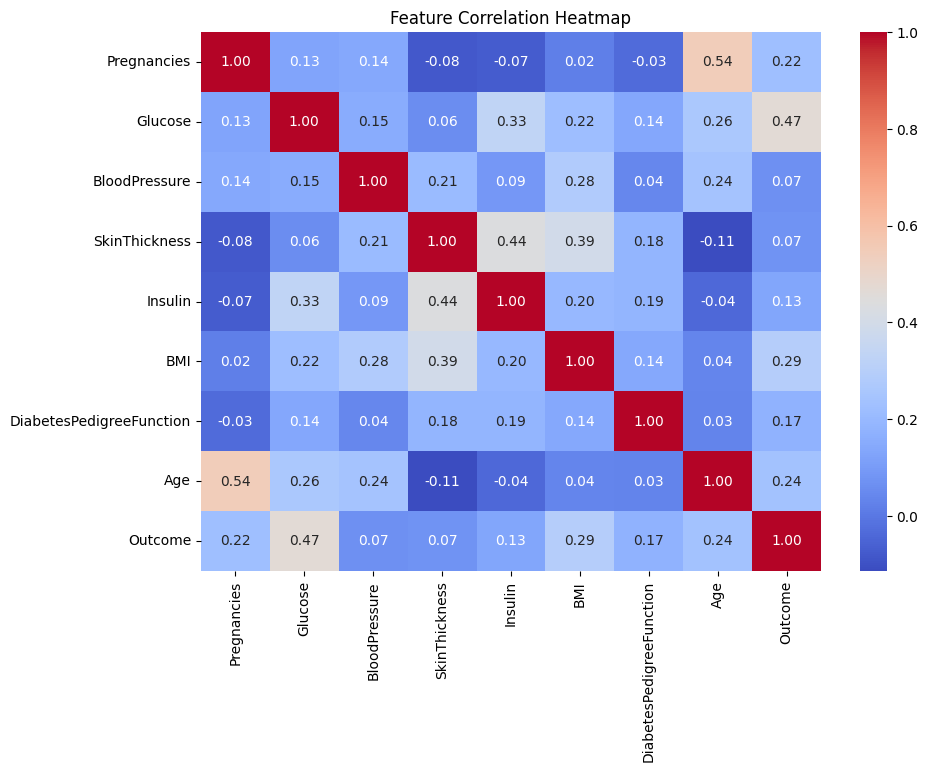

In [12]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [13]:
# Replace invalid zero values with NaN

columns_to_check = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[columns_to_check] = df[columns_to_check].replace(0, np.nan)

print("Zero values replaced with missing values.")

print("\nMissing values after preprocessing:")
print(df.isnull().sum())

Zero values replaced with missing values.

Missing values after preprocessing:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [14]:
# Separate features and target

X = df.drop('Outcome', axis=1)

y = df['Outcome']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (768, 8)
Target shape: (768,)


In [15]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [16]:
from sklearn.model_selection import GridSearchCV

# Create Machine Learning pipeline

pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear'))
])

# Hyperparameter tuning

param_grid = {
    'svm__C': [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model

grid_search.fit(X_train, y_train)

# Best model

model = grid_search.best_estimator_

print("Model trained successfully!")

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Model trained successfully!
Best Parameters: {'svm__C': 0.1}
Best Cross-Validation Accuracy: 0.775303212048514


In [17]:
# Predict test data

y_pred = model.predict(X_test)

print("Predictions completed successfully!")

print("\nActual values:")
print(y_test.values[:10])

print("\nPredicted values:")
print(y_pred[:10])

Predictions completed successfully!

Actual values:
[0. 0. 0. 1. 0. 0. 1. 1. 0. 0.]

Predicted values:
[1. 0. 0. 0. 0. 0. 0. 1. 0. 1.]


In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

MODEL PERFORMANCE
-------------------------
Accuracy : 70.78 %
Precision: 60.47 %
Recall   : 48.15 %
F1 Score : 53.61 %


In [19]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Non-Diabetic', 'Diabetic']
    )
)

Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.75      0.83      0.79       100
    Diabetic       0.60      0.48      0.54        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.66       154
weighted avg       0.70      0.71      0.70       154



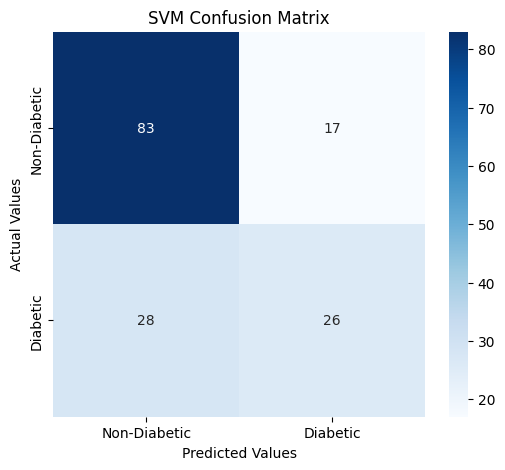

In [20]:
# Create confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [21]:
# Compare actual and predicted results

comparison = pd.DataFrame({
    'Actual Outcome': y_test.values,
    'Predicted Outcome': y_pred
})

display(comparison.head(15))

,Actual Outcome,Predicted Outcome
0,0.0,1.0
1,0.0,0.0
2,0.0,0.0
3,1.0,0.0
4,0.0,0.0
5,0.0,0.0
6,1.0,0.0
7,1.0,1.0
8,0.0,0.0
9,0.0,1.0


In [22]:
# Custom diabetes prediction function

def predict_diabetes(
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree,
    age
):

    patient_data = pd.DataFrame([[
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        diabetes_pedigree,
        age
    ]], columns=X.columns)

    prediction = model.predict(patient_data)

    if prediction[0] == 1:
        print("Prediction: Higher predicted diabetes risk.")
    else:
        print("Prediction: Lower predicted diabetes risk.")

    print("Note: This is an educational ML prediction, not a medical diagnosis.")

    return prediction[0]

In [23]:
# Example patient measurements

result = predict_diabetes(
    pregnancies=2,
    glucose=120,
    blood_pressure=70,
    skin_thickness=25,
    insulin=80,
    bmi=28.5,
    diabetes_pedigree=0.5,
    age=30
)

print("Predicted Class:", result)

Prediction: Lower predicted diabetes risk.
Note: This is an educational ML prediction, not a medical diagnosis.
Predicted Class: 0.0


In [24]:
# Save trained model

joblib.dump(model, 'diabetes_svm_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [25]:
from google.colab import files

files.download('diabetes_svm_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

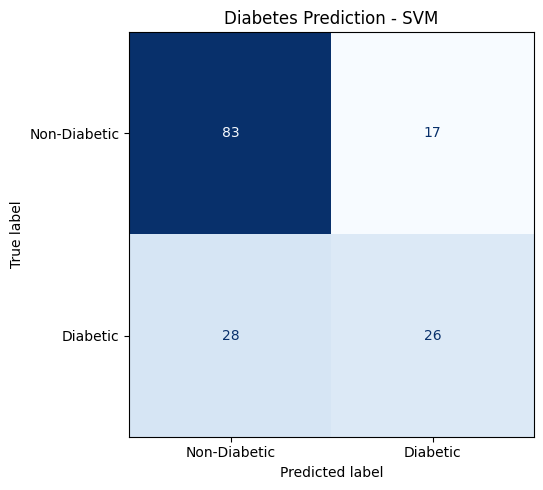

In [26]:
# Save confusion matrix image

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Non-Diabetic', 'Diabetic']
).plot(ax=ax, cmap='Blues', colorbar=False)

plt.title("Diabetes Prediction - SVM")
plt.tight_layout()

plt.savefig('confusion_matrix.png', dpi=300)

plt.show()

In [ ]:
files.download('confusion_matrix.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy :", round(test_accuracy * 100, 2), "%")

Training Accuracy: 78.18 %
Testing Accuracy : 70.78 %


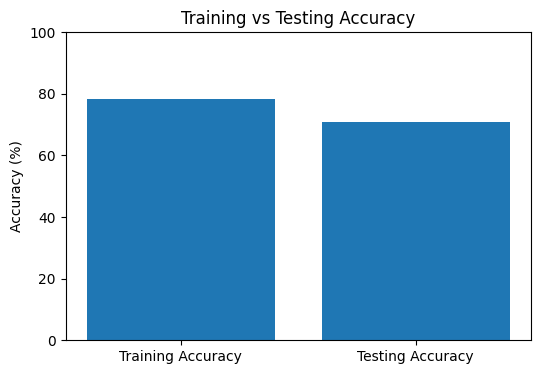

In [28]:
plt.figure(figsize=(6, 4))

plt.bar(
    ['Training Accuracy', 'Testing Accuracy'],
    [train_accuracy * 100, test_accuracy * 100]
)

plt.ylabel("Accuracy (%)")
plt.title("Training vs Testing Accuracy")
plt.ylim(0, 100)

plt.show()

In [29]:
requirements = """
numpy
pandas
matplotlib
seaborn
scikit-learn
joblib
"""

with open("requirements.txt", "w") as f:
    f.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [30]:
# Check all trained machine learning models and scalers

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print("Checking trained models and scalers...\n")

for name, obj in globals().copy().items():
    if isinstance(obj, (SVC, StandardScaler, Pipeline)):
        print("Variable Name:", name)
        print("Object Type:", type(obj))
        print("-" * 40)

Checking trained models and scalers...

Variable Name: pipeline
Object Type: <class 'sklearn.pipeline.Pipeline'>
----------------------------------------
Variable Name: model
Object Type: <class 'sklearn.pipeline.Pipeline'>
----------------------------------------


In [31]:
# Display dataset columns

print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [32]:
# Inspect the steps inside both pipelines

print("========== PIPELINE ==========")
print(pipeline)

print("\n========== MODEL ==========")
print(model)

print("\n========== PIPELINE STEPS ==========")
print("Pipeline steps:", pipeline.named_steps.keys())

print("\n========== MODEL STEPS ==========")
print("Model steps:", model.named_steps.keys())

========== PIPELINE ==========
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('svm', SVC(kernel='linear'))])

========== MODEL ==========
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('svm', SVC(C=0.1, kernel='linear'))])

========== PIPELINE STEPS ==========
Pipeline steps: dict_keys(['imputer', 'scaler', 'svm'])

========== MODEL STEPS ==========
Model steps: dict_keys(['imputer', 'scaler', 'svm'])


In [33]:
# Check prediction code and model configuration

print("Pipeline type:", type(pipeline))
print("Model type:", type(model))

print("\nPipeline final estimator:")
print(pipeline.steps[-1])

print("\nModel final estimator:")
print(model.steps[-1])

Pipeline type: <class 'sklearn.pipeline.Pipeline'>
Model type: <class 'sklearn.pipeline.Pipeline'>

Pipeline final estimator:
('svm', SVC(kernel='linear'))

Model final estimator:
('svm', SVC(C=0.1, kernel='linear'))


In [34]:
import joblib
import os

# Save the complete trained pipeline
joblib.dump(model, "diabetes_svm_model.pkl")

print("Model saved successfully!")

# Check saved file
print("File exists:", os.path.exists("diabetes_svm_model.pkl"))

Model saved successfully!
File exists: True


In [35]:
from google.colab import files

files.download("diabetes_svm_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:

%%writefile app.py

import streamlit as st
import numpy as np
import pandas as pd
import joblib

# Load trained SVM pipeline
model = joblib.load("diabetes_svm_model.pkl")

# Page configuration
st.set_page_config(
    page_title="Diabetes Prediction System",
    page_icon="🩺",
    layout="wide"
)

# Header
st.title("Diabetes Prediction System")
st.write(
    "A Machine Learning application using "
    "Support Vector Machine (SVM)."
)

st.divider()

st.subheader("Enter Patient Information")

# Input fields
col1, col2 = st.columns(2)

with col1:
    pregnancies = st.number_input(
        "Pregnancies",
        min_value=0,
        max_value=20,
        value=1
    )

    glucose = st.number_input(
        "Glucose Level",
        min_value=0.0,
        max_value=300.0,
        value=120.0
    )

    blood_pressure = st.number_input(
        "Blood Pressure",
        min_value=0.0,
        max_value=200.0,
        value=70.0
    )

    skin_thickness = st.number_input(
        "Skin Thickness",
        min_value=0.0,
        max_value=100.0,
        value=20.0
    )

with col2:
    insulin = st.number_input(
        "Insulin Level",
        min_value=0.0,
        max_value=900.0,
        value=80.0
    )

    bmi = st.number_input(
        "BMI",
        min_value=0.0,
        max_value=100.0,
        value=25.0
    )

    diabetes_pedigree = st.number_input(
        "Diabetes Pedigree Function",
        min_value=0.0,
        max_value=3.0,
        value=0.5
    )

    age = st.number_input(
        "Age",
        min_value=1,
        max_value=120,
        value=30
    )

st.divider()

# Prediction
if st.button("Predict Diabetes", type="primary"):

    input_data = pd.DataFrame(
        [[
            pregnancies,
            glucose,
            blood_pressure,
            skin_thickness,
            insulin,
            bmi,
            diabetes_pedigree,
            age
        ]],
        columns=[
            "Pregnancies",
            "Glucose",
            "BloodPressure",
            "SkinThickness",
            "Insulin",
            "BMI",
            "DiabetesPedigreeFunction",
            "Age"
        ]
    )

    prediction = model.predict(input_data)[0]

    st.subheader("Prediction Result")

    if prediction == 1:
        st.error(
            "The model predicts a higher likelihood "
            "of diabetes."
        )
    else:
        st.success(
            "The model predicts a lower likelihood "
            "of diabetes."
        )

    st.info(
        "This result is generated by a machine learning "
        "model and is not a medical diagnosis. "
        "Consult a qualified healthcare professional."
    )

st.divider()

st.caption(
    "Developed as an academic Machine Learning project "
    "using Python, Streamlit and SVM."
)


Writing app.py


In [37]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
%%writefile requirements.txt
streamlit
numpy
pandas
scikit-learn
joblib

Overwriting requirements.txt
